# Used-Car Pricing Cycle vs. CarMax (KMX) and Carvana (CVNA) — Alt-Data Research Note

**Thesis question:** what does the public used-car price signal say about the two largest U.S. used-car retailers,
and is Carvana taking share from CarMax?

**Data (all public, pulled Nov 2026):**
* BLS CPI — *Used cars & trucks* (CUSR0000SETA02), *New vehicles* (CUSR0000SETA01), *All items* (CPIAUCSL), monthly, via FRED
* SEC EDGAR XBRL company facts — quarterly revenue and gross profit for CarMax (fiscal year ends Feb) and Carvana (calendar year)

*Note:* XBRL quarterly facts exist only for Q1–Q3; fourth quarters are reported inside the annual 10-K, so they
are missing here and all growth rates compare the same fiscal quarter year over year.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, pathlib
CH = pathlib.Path("charts"); CH.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
BLUE, ORANGE, GREY, RED = "#2563eb", "#ea580c", "#9ca3af", "#dc2626"
cpi = pd.read_csv("data/fred_cpi_vehicles.csv", parse_dates=["month"]).set_index("month")
sec = pd.read_csv("data/sec_quarterly.csv", parse_dates=["quarter_end"])

## 1. The used-car price cycle

Used-car CPI: 2019 avg 139.8 → peak 216.9 in Feb 2022 (+55%) → 179.9 in Oct 2026 (-17% from peak, still +29% vs 2019)
Latest YoY: used -3.3%, new +0.7%
Used/new price ratio: 2019 0.95, peak 1.29, latest 1.00


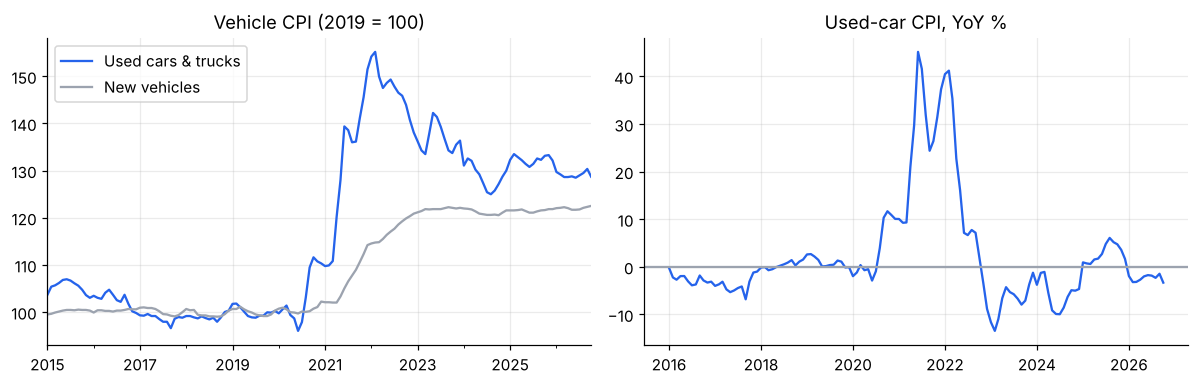

In [2]:
cpi["used_real"] = cpi.cpi_used_cars / cpi.cpi_all_items.interpolate() * 100
cpi["used_yoy"] = cpi.cpi_used_cars.pct_change(12)
cpi["new_yoy"] = cpi.cpi_new_vehicles.pct_change(12)
pre = cpi.loc["2019-01":"2019-12", "cpi_used_cars"].mean()
peak_m = cpi.cpi_used_cars.idxmax(); peak = cpi.cpi_used_cars.max()
last_m = cpi.index[-1]; last = cpi.cpi_used_cars.iloc[-1]
print(f"Used-car CPI: 2019 avg {pre:.1f} → peak {peak:.1f} in {peak_m:%b %Y} ({peak/pre-1:+.0%}) → {last:.1f} in {last_m:%b %Y} "
      f"({last/peak-1:+.0%} from peak, still {last/pre-1:+.0%} vs 2019)")
print(f"Latest YoY: used {cpi.used_yoy.iloc[-1]:+.1%}, new {cpi.new_yoy.iloc[-1]:+.1%}")
rel = cpi.cpi_used_cars / cpi.cpi_new_vehicles
print(f"Used/new price ratio: 2019 {rel['2019'].mean():.2f}, peak {rel.max():.2f}, latest {rel.iloc[-1]:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
(cpi[["cpi_used_cars", "cpi_new_vehicles"]] / cpi.loc["2019-01":"2019-12", ["cpi_used_cars", "cpi_new_vehicles"]].mean() * 100).plot(
    ax=ax[0], color=[BLUE, GREY]); ax[0].legend(["Used cars & trucks", "New vehicles"]); ax[0].set_title("Vehicle CPI (2019 = 100)"); ax[0].set_xlabel("")
ax[1].plot(cpi.index, cpi.used_yoy * 100, color=BLUE); ax[1].axhline(0, color=GREY)
ax[1].set_title("Used-car CPI, YoY %"); fig.tight_layout(); fig.savefig(CH / "01_used_car_cpi.png", bbox_inches="tight")

## 2. Company fundamentals (SEC XBRL)

In [3]:
q = sec.pivot_table(index=["ticker", "quarter_end"], columns="metric", values="usd_millions").reset_index()
q["gm"] = q.GP / q.REV
q = q.sort_values(["ticker", "quarter_end"])
# same fiscal quarter one year earlier (quarter ends ±5 days)
prev = q[["ticker", "quarter_end", "REV", "GP"]].copy(); prev["quarter_end"] += pd.DateOffset(years=1)
q = pd.merge_asof(q.sort_values("quarter_end"), prev.sort_values("quarter_end"), on="quarter_end", by="ticker",
                  direction="nearest", tolerance=pd.Timedelta("5D"), suffixes=("", "_ly"))
q["rev_yoy"] = q.REV / q.REV_ly - 1
q["gp_yoy"] = q.GP / q.GP_ly - 1
q = q.sort_values(["ticker", "quarter_end"])
recent = q[q.quarter_end >= "2025-01-01"]
recent[["ticker", "quarter_end", "REV", "GP", "gm", "rev_yoy"]].round(3)

/tmp/ipykernel_946/647421820.py:12: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  recent[["ticker", "quarter_end", "REV", "GP", "gm", "rev_yoy"]].round(3)


metric,ticker,quarter_end,REV,GP,gm,rev_yoy
67,CVNA,2025-03-31,4232.0,929.0,0.220,0.383
69,CVNA,2025-06-30,4840.0,1064.0,0.220,0.419
71,CVNA,2025-09-30,5647.0,1148.0,0.203,0.545
73,CVNA,2026-03-31,6432.0,1271.0,0.198,0.520
75,CVNA,2026-06-30,7376.0,1384.0,0.188,0.524
77,CVNA,2026-09-30,8040.0,1521.0,0.189,0.424
68,KMX,2025-05-31,7547.0,894.0,0.118,0.061
70,KMX,2025-08-31,6595.0,718.0,0.109,-0.060
72,KMX,2025-11-30,5794.0,590.0,0.102,-0.069
74,KMX,2026-05-31,8014.0,854.0,0.107,0.062


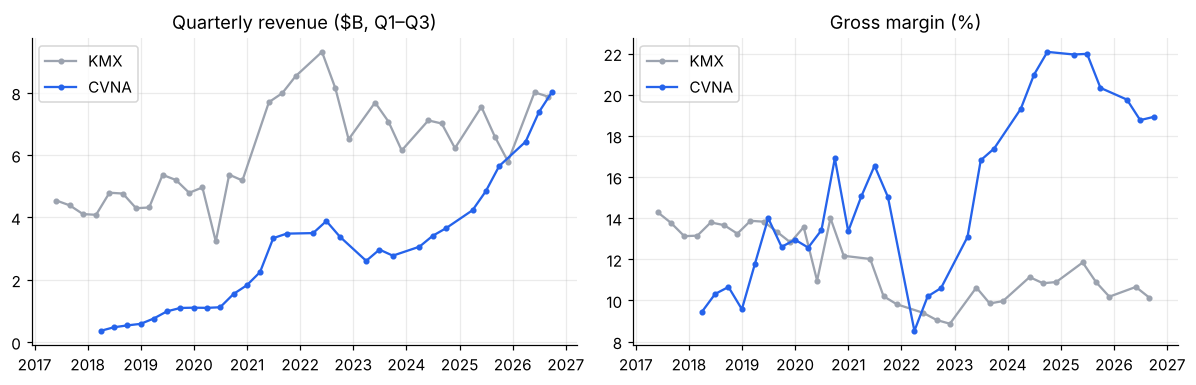

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for t, c in [("KMX", GREY), ("CVNA", BLUE)]:
    g = q[(q.ticker == t) & q.REV.notna()]
    ax[0].plot(g.quarter_end, g.REV / 1000, marker="o", ms=3, color=c, label=t)
    g2 = q[(q.ticker == t) & q.gm.notna()]
    ax[1].plot(g2.quarter_end, g2.gm * 100, marker="o", ms=3, color=c, label=t)
ax[0].set_title("Quarterly revenue ($B, Q1–Q3)"); ax[1].set_title("Gross margin (%)"); ax[0].legend(); ax[1].legend()
fig.tight_layout(); fig.savefig(CH / "02_revenue_margin.png", bbox_inches="tight")

## 3. Share shift: Carvana revenue as % of CarMax
CarMax's fiscal quarters end one month before Carvana's (May/Aug/Nov vs Jun/Sep/Dec), so each Carvana quarter is
paired with the CarMax quarter ending ~1 month earlier (only Jun- and Sep-quarter pairs exist in the Q1–Q3 data).

quarter_end   CVNA    KMX  cvna_pct_kmx
 2024-06-30 3410.0 7113.0          0.48
 2024-09-30 3655.0 7014.0          0.52
 2025-06-30 4840.0 7547.0          0.64
 2025-09-30 5647.0 6595.0          0.86
 2026-06-30 7376.0 8014.0          0.92
 2026-09-30 8040.0 7878.0          1.02


/tmp/ipykernel_946/3769824407.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(m.tail(6).round(2).to_string(index=False))


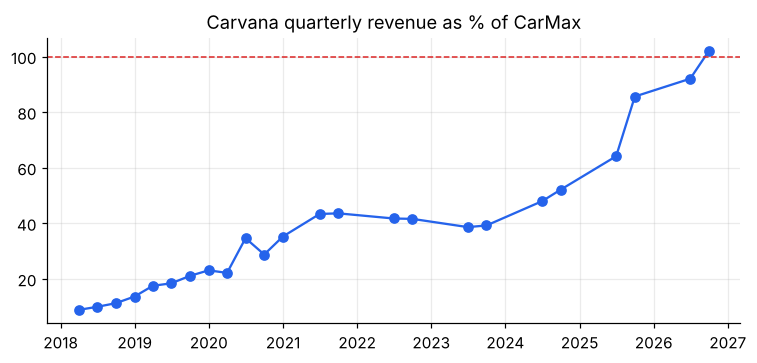

In [5]:
k = q[q.ticker == "KMX"][["quarter_end", "REV"]].dropna().rename(columns={"REV": "KMX"})
c = q[q.ticker == "CVNA"][["quarter_end", "REV"]].dropna().rename(columns={"REV": "CVNA"})
m = pd.merge_asof(c.sort_values("quarter_end"), k.sort_values("quarter_end"), on="quarter_end",
                  direction="backward", tolerance=pd.Timedelta("35D")).dropna()
m["cvna_pct_kmx"] = m.CVNA / m.KMX
print(m.tail(6).round(2).to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(m.quarter_end, m.cvna_pct_kmx * 100, marker="o", color=BLUE); ax.axhline(100, color=RED, ls="--", lw=1)
ax.set_title("Carvana quarterly revenue as % of CarMax"); fig.tight_layout(); fig.savefig(CH / "03_share_shift.png", bbox_inches="tight")

## 4. Does the used-price signal lead the fundamentals?
Correlate each company's same-quarter YoY revenue growth with used-car CPI YoY (quarter average), with 0–2 quarter lags.

In [6]:
cq = cpi.used_yoy.resample("QE").mean()
rows = []
for t in ["KMX", "CVNA"]:
    g = q[(q.ticker == t)].dropna(subset=["rev_yoy"]).set_index("quarter_end")
    for lag in [0, 1, 2]:
        x = cq.shift(lag).reindex(g.index, method="nearest")
        rows.append({"ticker": t, "lag_quarters": lag, "corr_rev_yoy": g.rev_yoy.corr(x), "n": len(g)})
corr = pd.DataFrame(rows)
corr.round(2)

,ticker,lag_quarters,corr_rev_yoy,n
0,KMX,0,0.80,28
1,KMX,1,0.47,28
2,KMX,2,0.35,28
3,CVNA,0,0.58,26
4,CVNA,1,0.28,26
5,CVNA,2,0.05,26


## Research note (summary)
* **Prices have normalised but not reset.** Used-car CPI rose 55% from its 2019 average to a Feb 2022 peak, has fallen
  17% since, and is still 29% above 2019 (Oct 2026, −3.3% YoY). The used/new price ratio is back to 1.00 from a 1.29 peak,
  so the "used is scarce" tailwind is gone.
* **Carvana has caught CarMax.** Carvana's quarterly revenue went from 48% of CarMax's (Jun-2024 quarter) to **102%**
  (Sep-2026 quarter: $8.04B vs $7.88B), growing 42–55% YoY through 2025–26 at a ~19–22% gross margin vs CarMax's ~10–12%.
  Carvana's margin has eased from 22% to ~19% as it scaled — the metric to watch.
* **CarMax is the cyclical one.** Its YoY revenue growth moves with used-car CPI YoY (correlation 0.80 same quarter,
  fading to 0.35 at a 2-quarter lag), so flat-to-falling used prices are a headwind to reported sales even at steady units.
* **What to watch next:** monthly used-car CPI (mid-month release), Manheim wholesale index, CVNA retail units and GPU.

*Not investment advice — a portfolio exercise in building an alt-data view from public sources.*